### Long-Shot Term Memory (LSTM) Model

Here we develop a LSTM for three environmental variable forecasting.

In [1]:
import pandas as pd 
import numpy as np 
import matplotlib.pyplot as plt
import seaborn as sns
import os
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, r2_score
from torch.nn import LSTM, Module, Linear, ReLU, Sequential
import torch 


In [2]:
wkdir = r"C:/Users/agbob/OSUCLAB/ADD/FOSSE/osuc_digital_twin/"
data_dir = wkdir + "data/"

file_name = "cleaned_data.csv"

path = os.path.join(data_dir, file_name)

In [3]:
data = pd.read_csv(path, sep=",")
data["date"] = pd.to_datetime(data["date"], format="%Y-%m-%d %H:%M:%S")
data.set_index("date", inplace=True)
data.head()


,temperature_om,humidity_om,pressure_om,wind_speed_om,wind_direction_om,precipitation_om,soil_temperature_6cm_om,soil_temperature_18cm_om,soil_temperature_54cm_om,solarRadiation,...,temp_74cm_imputed,air_temperature_imputed,humi_6cm_imputed,humi_18cm_imputed,humi_54cm_imputed,humi_74cm_imputed,pH_6cm_imputed,pH_18cm_imputed,pH_54cm_imputed,pH_74cm_imputed
date,,,,,,,,,,,,,,,,,,,,,
2025-09-29 08:00:00,11.580501,86.0,1023.599976,5.506941,348.690094,0.0,10.980500,12.680500,14.9305,185.03,...,0,0,0,0,0,0,0,0,0,0
2025-09-29 09:00:00,13.980500,79.0,1023.700012,8.427383,19.983198,0.0,12.980500,12.680500,14.9305,245.69,...,0,0,0,0,0,0,0,0,0,0
2025-09-29 10:00:00,15.880500,75.0,1023.299988,10.086427,34.824570,0.0,15.130500,12.830501,14.8805,316.08,...,0,0,0,0,0,0,0,0,0,0
2025-09-29 11:00:00,17.280499,69.0,1023.000000,11.720751,42.510403,0.0,17.030499,13.180500,14.8805,318.51,...,0,0,0,0,0,0,0,0,0,0
2025-09-29 12:00:00,18.130499,61.0,1022.799988,12.096214,53.471054,0.0,18.030499,13.580501,14.8805,114.90,...,0,0,0,0,0,0,0,0,0,0


In [4]:
columns = [
    'temp_6cm', 'humi_6cm', 'pH_6cm',
    'temp_18cm', 'humi_18cm', 'pH_18cm',
    'temp_54cm', 'humi_54cm', 'pH_54cm',
    'temp_74cm', 'humi_74cm', 'pH_74cm'
]

df = data[columns].copy()
df.dropna(inplace=True)

In [5]:
df.head()

,temp_6cm,humi_6cm,pH_6cm,temp_18cm,humi_18cm,pH_18cm,temp_54cm,humi_54cm,pH_54cm,temp_74cm,humi_74cm,pH_74cm
date,,,,,,,,,,,,
2025-09-29 08:00:00,13.10,14.06,6.40,13.40,18.80,6.81,14.00,17.11,8.50,13.13,16.94,6.30
2025-09-29 09:00:00,13.27,14.09,6.30,13.55,18.80,6.97,14.04,17.18,8.32,13.62,17.00,6.42
2025-09-29 10:00:00,13.76,14.17,6.33,13.97,18.93,7.01,14.20,17.26,8.19,14.68,17.16,6.44
2025-09-29 11:00:00,14.71,14.50,6.44,15.14,19.11,6.90,14.78,17.41,8.27,16.67,17.38,6.38
2025-09-29 12:00:00,15.98,14.37,6.41,16.70,19.18,7.14,15.76,17.50,8.43,18.34,17.30,6.49


In [6]:
class TimeSeriesDataset(torch.utils.data.Dataset):
    def __init__(self, data, window_size):
        self.data = data
        self.window_size = window_size

    def __len__(self):
        return len(self.data) - self.window_size

    def __getitem__(self, idx):
        x = self.data[idx:idx+self.window_size]
        y = self.data[idx+self.window_size]
        return torch.tensor(x, dtype=torch.float32), torch.tensor(y, dtype=torch.float32)

In [7]:
class LSTMModel(Module): 
    def __init__(self, input_size, output_size, window_size=10, hidden_size=128, num_layers=2):
        super(LSTMModel, self).__init__()
        self.hidden_size = hidden_size
        self.num_layers = num_layers
        self.window_size = window_size
        self.lstm = LSTM(input_size, hidden_size, num_layers, batch_first=True)
        self.fc1 = Linear(hidden_size, hidden_size//2)
        self.relu = ReLU()
        self.fc2 = Linear(hidden_size//2, output_size)
        self.optimizer = torch.optim.Adam(self.parameters(), lr=0.001)
        self.train_losses = []
        self.val_losses = []

    def forward(self, x):
        h0 = torch.zeros(self.num_layers, x.size(0), self.hidden_size).to(x.device)
        c0 = torch.zeros(self.num_layers, x.size(0), self.hidden_size).to(x.device)

        out, _ = self.lstm(x, (h0, c0))
        out = self.fc1(out[:, -1, :])
        out = self.relu(out)
        out = self.fc2(out)
        return out
    
    def save_model(self, epoch, path='models/'):

        if not os.path.exists(path):
            os.makedirs(path)
        torch.save(self.state_dict(), os.path.join(path, f'lstm_model_epoch_{epoch}.pth'))
    
    def fit(self, data, window_size=10, epochs=50, batch_size=32, criterion=torch.nn.MSELoss(), validation_split=0.2):
        self.train()

        train_data, val_data = train_test_split(data, test_size=validation_split, shuffle=False)

        if window_size != self.window_size:
            self.window_size = window_size
    
        train_dataset = TimeSeriesDataset(train_data, self.window_size)
        validation_dataset = TimeSeriesDataset(val_data, self.window_size)
        train_loader = torch.utils.data.DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
        val_loader = torch.utils.data.DataLoader(validation_dataset, batch_size=batch_size, shuffle=True)

        for epoch in range(epochs):
            total_loss = 0
            for inputs, targets in train_loader:
                self.optimizer.zero_grad()
                outputs = self(inputs)
                loss = criterion(outputs, targets)
                loss.backward()
                self.optimizer.step()
                total_loss += loss.item()
            avg_loss = total_loss / len(train_loader)
            self.train_losses.append(avg_loss)
            # Validation loss
            val_loss = self.evaluate(val_loader, criterion)
            self.val_losses.append(val_loss)
            print(f'Epoch [{epoch+1}/{epochs}], Loss: {avg_loss:.4f}, Val Loss: {val_loss:.4f}')

    def evaluate(self, test_loader, criterion):
        self.eval()
        with torch.no_grad():
            total_loss = 0
            for inputs, targets in test_loader:
                outputs = self(inputs)
                loss = criterion(outputs, targets)
                total_loss += loss.item()
        return total_loss / len(test_loader)    
    
    def predict(self, input_seq):
        self.eval()

        with torch.no_grad():
            input_tensor = torch.tensor(input_seq, dtype=torch.float32).unsqueeze(0)
            output = self(input_tensor)
        return output.squeeze(0).numpy()

In [8]:
model = LSTMModel(input_size=12, output_size=12, hidden_size=128, num_layers=2)


In [9]:
df_train, df_test = train_test_split(df, test_size=0.2, shuffle=False)
model.fit(df_train.values, window_size=10, epochs=12, batch_size=32)

Epoch [1/12], Loss: 183.7099, Val Loss: 148.0021
Epoch [2/12], Loss: 150.0352, Val Loss: 99.5657
Epoch [3/12], Loss: 92.8622, Val Loss: 49.8814
Epoch [4/12], Loss: 37.5266, Val Loss: 14.2258
Epoch [5/12], Loss: 9.2695, Val Loss: 6.6633
Epoch [6/12], Loss: 3.0263, Val Loss: 4.9193
Epoch [7/12], Loss: 2.0140, Val Loss: 3.2332
Epoch [8/12], Loss: 1.6469, Val Loss: 3.3337
Epoch [9/12], Loss: 1.6536, Val Loss: 3.0323
Epoch [10/12], Loss: 1.6046, Val Loss: 3.2810
Epoch [11/12], Loss: 1.6075, Val Loss: 3.2429
Epoch [12/12], Loss: 1.6154, Val Loss: 3.3427


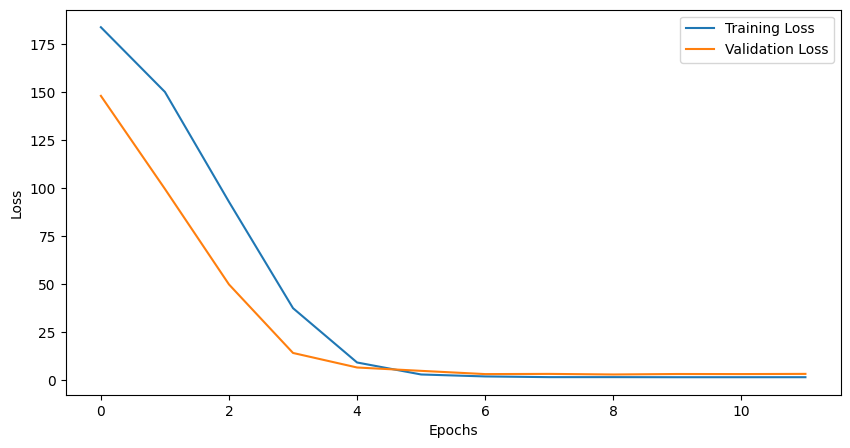

In [10]:
# plot training and validation loss curves (if stored during training)

plt.figure(figsize=(10,5))
plt.plot(model.train_losses, label='Training Loss')
plt.plot(model.val_losses, label='Validation Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.show()

In [11]:
# test
y_preds = []
window_size = 10

for i in range(len(df_test) - window_size):
    input_seq = df_test.values[i:i+window_size]
    y_pred = model.predict(input_seq)
    y_preds.append(y_pred)
y_preds = np.array(y_preds)
y_true = df_test.values[window_size:]
# Evaluate
mse = mean_squared_error(y_true, y_preds)
r2 = r2_score(y_true, y_preds)
print(f'Test MSE: {mse:.4f}, R2 Score: {r2:.4f}')

Test MSE: 9.2901, R2 Score: -14.3277


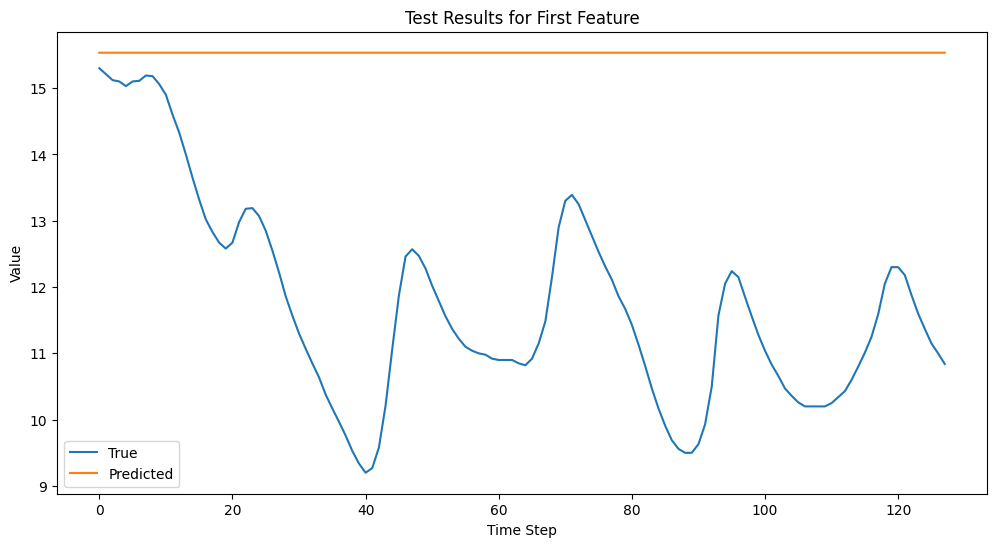

In [12]:
# plot test results for first feature
plt.figure(figsize=(12,6))
plt.plot(y_true[:, 0], label='True')
plt.plot(y_preds[:, 0], label='Predicted')
plt.title('Test Results for First Feature')
plt.xlabel('Time Step')
plt.ylabel('Value')
plt.legend()
plt.show()

In [13]:
# print 10 predictions for the first variable
for i in range(10):
    print(f'True: {y_true[i, 0]}, Predicted: {y_preds[i, 0]}')

True: 15.3, Predicted: 15.53342342376709
True: 15.21, Predicted: 15.533429145812988
True: 15.12, Predicted: 15.533429145812988
True: 15.1, Predicted: 15.533426284790039
True: 15.03, Predicted: 15.533426284790039
True: 15.1, Predicted: 15.533426284790039
True: 15.11, Predicted: 15.533430099487305
True: 15.19, Predicted: 15.53343391418457
True: 15.18, Predicted: 15.533434867858887
True: 15.06, Predicted: 15.533434867858887
